# Results: original and estimated dates

In [1]:
import sys
import tempfile

import duckdb
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Dates of `individual_enriched` (ingested by `ingest_dates.py` from notebooks 01, 02 and 04):
- **Original**: the date comes from Wikidata (`source = 'wikidata'`), coarse dates included.
- **Estimated**: the date was imputed (`source = 'estimated'`).
- **Original work period**: first and last dated works (inception, else publication) in different years.
- **Estimated work period**: first and last work years imputed from the birth and death dates.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
dates = con.sql('''
    SELECT entity.qid AS qid,
           birth_date.year AS birth_year,
           birth_date.source AS birth_source,
           death_date.source AS death_source,
           first_work_date.source AS work_source,
           first_work_date.year AS first_work_year,
           last_work_date.year AS last_work_year
    FROM individual_enriched
''').pl()
assert dates['qid'].is_unique
print(f'{dates.height:,} individuals')
dates.sample(5, seed=42)

13,002,897 individuals


qid,birth_year,birth_source,death_source,work_source,first_work_year,last_work_year
str,i64,str,str,str,i64,i64
"""Q76135520""",null,null,null,null,null,null
"""Q132673317""",1942,"""wikidata""",null,"""estimated""",1977,2000
"""Q98085680""",2001,"""wikidata""",null,null,null,null
"""Q60836732""",1938,"""wikidata""",null,"""estimated""",1973,1996
"""Q75670807""",null,null,null,null,null,null


## Counts

In [3]:
period = pl.col('first_work_year') < pl.col('last_work_year')
counts = {
    'Original birth date': pl.col('birth_source') == 'wikidata',
    'Estimated birth date': pl.col('birth_source') == 'estimated',
    'Original death date': pl.col('death_source') == 'wikidata',
    'Estimated death date': pl.col('death_source') == 'estimated',
    'Original work period': (pl.col('work_source') == 'dated works') & period,
    'Estimated work period': pl.col('work_source') == 'estimated',
}
results = pl.DataFrame([
    {'dates': name, 'individuals': dates.filter(rule).height, 'share of the database (%)': 100 * dates.filter(rule).height / dates.height}
    for name, rule in counts.items()
])
single_year = dates.filter((pl.col('work_source') == 'dated works') & ~period).height
print(f'{single_year:,} individuals with dated works all in one year: neither an original nor an estimated work period')

250,976 individuals with dated works all in one year: neither an original nor an estimated work period


### Table: original and estimated dates

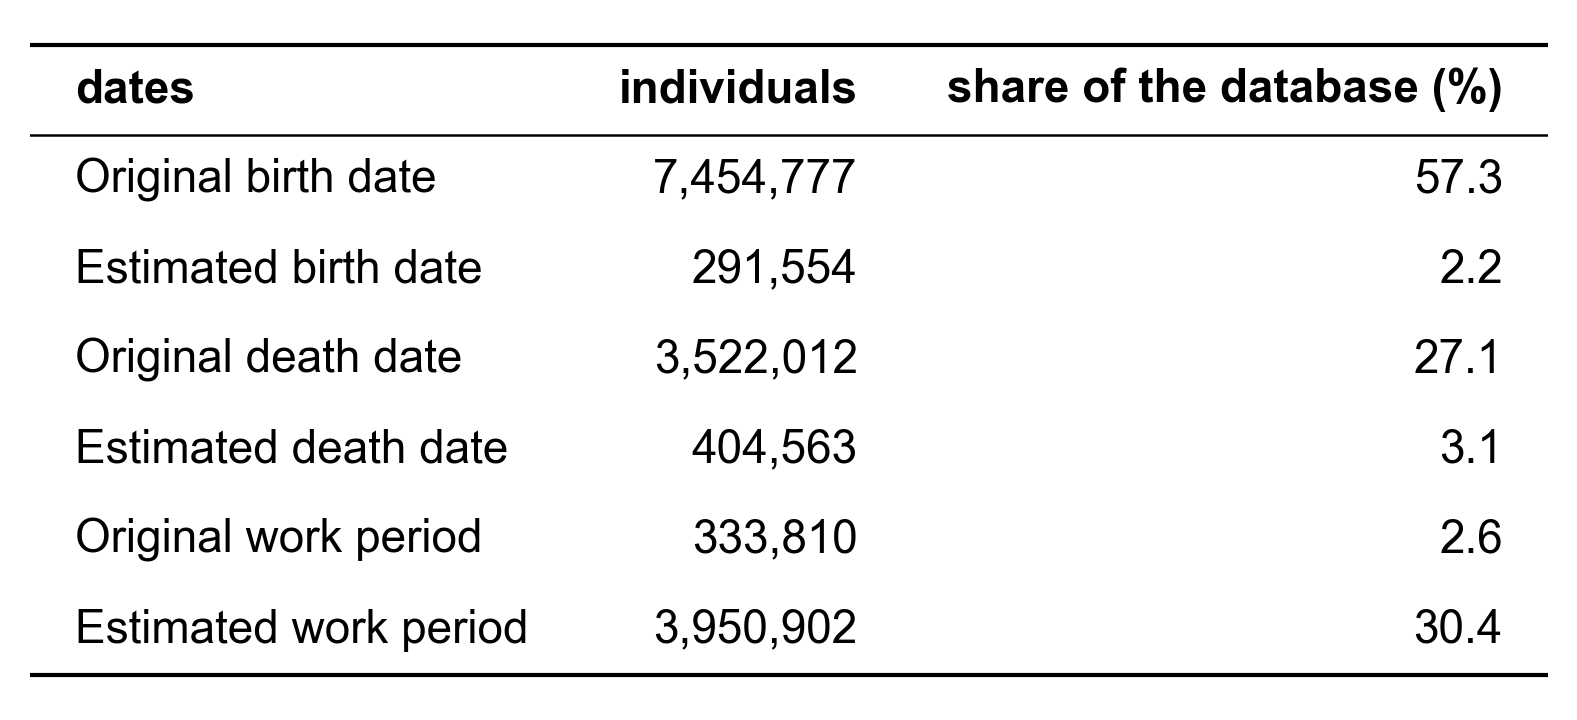

In [4]:
show_table(results, decimals=1)

## Without individuals born after 1920
Individuals with an original or estimated birth year after 1920 are removed; individuals without a birth year are kept. Shares are relative to the remaining individuals.

In [5]:
before_1920 = dates.filter(pl.col('birth_year').is_null() | (pl.col('birth_year') <= 1920))
results_before_1920 = pl.DataFrame([
    {'dates': name, 'individuals': before_1920.filter(rule).height, 'share of the database (%)': 100 * before_1920.filter(rule).height / before_1920.height}
    for name, rule in counts.items()
])
print(f'{dates.height - before_1920.height:,} individuals born after 1920 removed, {before_1920.height:,} remaining')

4,552,759 individuals born after 1920 removed, 8,450,138 remaining


### Table: original and estimated dates, individuals born up to 1920

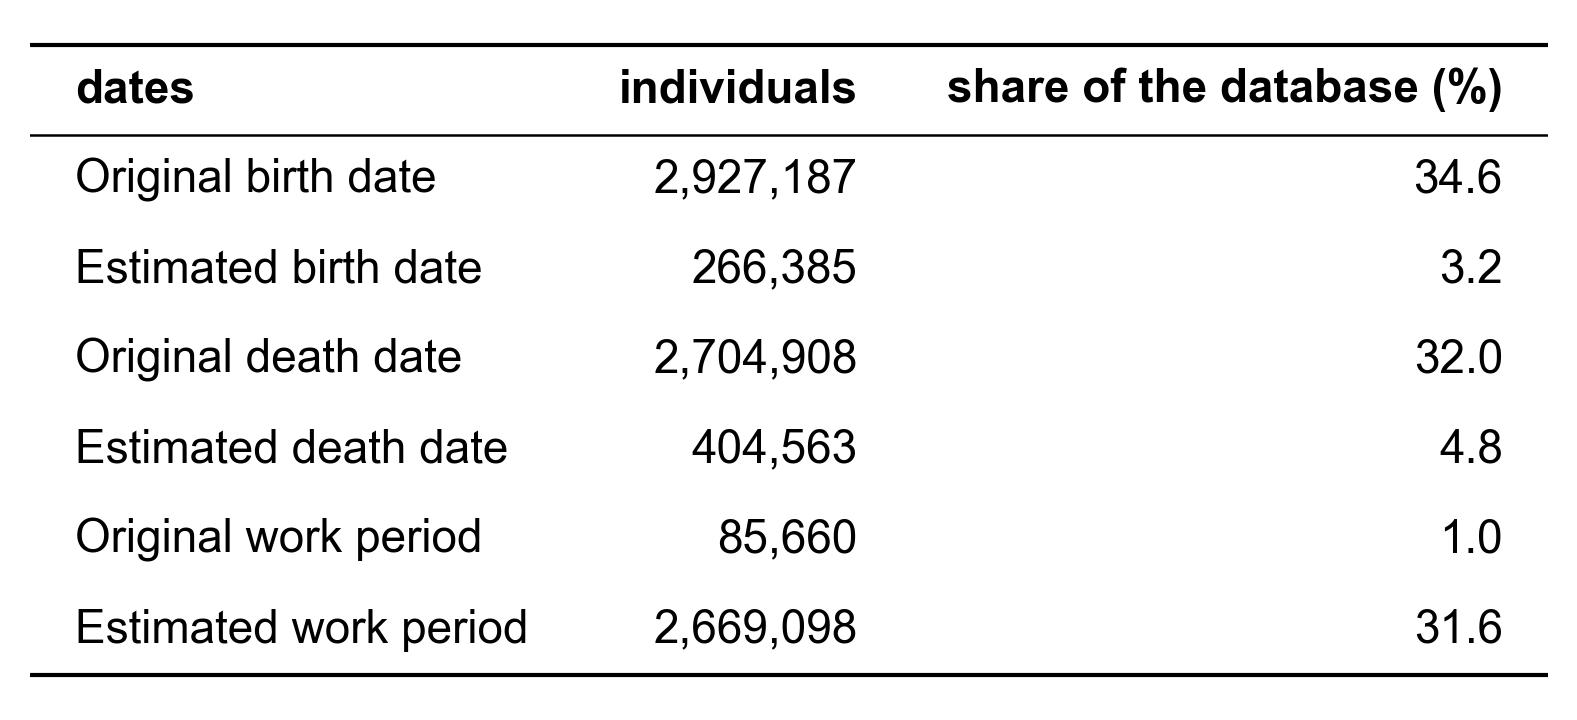

In [6]:
show_table(results_before_1920, decimals=1)